# Quantitative results
One run (`RUN`, saved eval outputs at `EPOCH`) → one per-sample table `df = load_samples(RUN, EPOCH, METRIC)` → four panels in a 2 × 2 figure:
generalization | object (row 1), seen vs. unseen | box (row 2). No panel titles; an empty band above each row (and a free spot at the top-left, left of the legend) is left for hand-placed (a)–(d) labels.
Each panel is two steps: an aggregation `<panel>_data(df)` that turns `df` into the panel's config entry, then a draw function `draw_<panel>(ax, cfg)` that only plots.
`panel_fig(letter, cfg)` shows one panel on its own; `plot_all(cfg)` draws all four with the same draw functions, so a panel looks identical alone and in the joint figure. Nothing is saved until the last cell.
The speakers panel (`speakers_data`, `draw_speakers`) is kept but not drawn.

`cfg` is a plain dict with the same keys as `DEFAULT_CFG` (the hand-typed values of the first draft). Replace any entry, e.g. `cfg["boxes"] = DEFAULT_CFG["boxes"]`, to plot fixed values instead of the computed ones.

**Data.** One row per (sample, model). WhisperBox: the run's saved predictions (eager fp32 eval, eval splits + the train-set eval), binarized at p > .08, scored against the 64×64 true mask (`score.truth`). Empty-box samples are dropped. **Nearest neighbour (NN)**: for each eval sample, the train sample of the same box and same object(s) with the closest input spectrum (log band-mean |FFT|, 30 bands per laser and channel, z-scored per box); its true mask is the prediction. If the box has no train sample of that object, any train sample of that box (`nn_match = "box"`). NN on train is a self-match (100 by construction).

**Splits by training frequency.** A *condition* is one eval split (e.g. `two-cubes`); its training count `n_train` = train samples with the same (box, objects, layout) as the split's eval samples. Scope = the old ID ∪ OOD (`id`, `multiple` and `EvalSummary.OOD`; control / broken / unseen-angle / unseen-position / unseen-rotated-object are left out as before).
- **unseen eval**: the held-out factor never occurs in training: categories in `UNSEEN_BY_CONSTRUCTION` (unseen object / speaker / laser), or `n_train = 0` in that box (lids, sideways soap dispenser in gastronorm / plastic, cylinders outside cardboard).
- **hard eval** (code: `rare`): trained, but the condition has fewer than `RARE_MAX_TRAIN` = 1000 train samples summed over the boxes (multi-object scenes, rotated soap dispenser / cube and cylinders in cardboard).
- **easy eval** (code: `frequent`): trained with ≥ `RARE_MAX_TRAIN` samples (the four single objects at held-out positions).

**Statistics.** Each bar is the mean of the per-sample metric (in %); the std and n are computed and stored in `cfg` (`{"mean", "std", "n"}`) but not drawn.

In [1]:
RUN, EPOCH, METRIC = "decres-rescale-aug10-v1", 300, "iou"   # METRIC: "iou" or "dice"
OBJECT_IMAGES = {"cube": "assets/objects/individual/cube.png", "vase": "assets/objects/individual/vase.png", "soap-dispenser": "assets/objects/individual/soap.png", "candle": "assets/objects/individual/candle.png",
                 "two-cubes": "assets/objects/individual/two_cubes.png", "cube-vase": "assets/objects/individual/cube_and_vase.png",
                 "coffee-pot": "assets/objects/individual/coffee_pot.png", "tomato-sauce": "assets/objects/individual/tomato_sauce.png"}   # relative to the repo root; a missing file = empty thumbnail slot
OVERHEAD_EMPTY_BOX = {"gastro": "assets/overhead_empty_box/gastronorm.png", "plastic": "assets/overhead_empty_box/plastic.png", "cardboard": "assets/overhead_empty_box/cardboard.png"}
PROFILE_EMPTY_BOX = {"gastro": "assets/profile_empty_box/gastronorm.png", "plastic": "assets/profile_empty_box/plastic.png", "cardboard": "assets/profile_empty_box/cardboard.png"}   # drawn under the box bars
FACTOR_IMAGES = {"object": "assets/objects/all_objects.png", "speaker": "assets/speakers.pdf", "laser speckle": "assets/laser_shift_box.svg",   # seen vs. unseen panel: image above a factor (centred over its pair)
                 "rotation": tuple(f"assets/objects/rotated_soap/soap_rotated_{k}.png" for k in (2, 3))}   # a tuple = images side by side
OUT_DIR = "figures/quantitative_results"   # relative to the repo root

## Style guides
The figure follows these, in this order of priority. ✓ = enforced in code (and checked by the asserts in *Checks*), ✎ = left to the caption / text.

1. **CVPR author kit** (single column, three rows): width = `\columnwidth` = 3.25 in, included at native size (`\includegraphics` without scaling) so 1 pt in the figure = 1 pt in the paper ✓; vector output (SVG, text converted to paths so it renders identically without the font) ✓; body font Latin Modern ✓.
2. **Readability in print** (no figure text much smaller than the 9 pt caption): legend / axis label 7 pt, ticks and x labels 6.3 pt ✓. *Deviation*: the numbers inside the bars are 5.4 pt so they fit inside a 0.115 in bar; the assert enforces ≥ 5.4 pt, not 7 pt.
3. **Tufte, data-ink**: no titles, no top/right spines, light gridlines only at 0/25/50/75/100, each value written once inside its bar on a common baseline; no error bars (std is computed and kept in `cfg`) ✓.
4. **Consistent encoding** (one meaning per colour in every panel): green = train, blue = easy eval, light blue = hard eval, orange = unseen eval, gray + hatch = nearest-neighbour baseline; no per-object or per-material colours ✓. Easy and hard are one hue family (both seen in training), with clearly different lightness; light blue (L = .61) is also lighter than the NN gray (L = .47), which carries a hatch as a second cue, so all five survive grayscale ✓. One legend for the whole figure ✓.
5. **Consistent layout**: three rows (baselines + boxes | objects | seen vs. unseen), ONE step (spacing between neighbouring x labels) in every panel, set so the object row fills the width; one bar width (`BAR_W_IN`) and one pair spacing everywhere; rows share the left edge, rows 1-2 the right edge; gap between panels ≥ one step ✓ (asserted from the drawn bar centres). Category images directly above their bar, each fitted into one shared box ✓; legend in the free space right of the last row ✓; no text overlaps ✓.
6. **Labels**: horizontal everywhere, two lines where needed (no hyphenation) ✓. Integer percent everywhere, y ticks 0 / 50 / 100, metric with unit on the axis ✓; one vocabulary: train / easy / hard / unseen eval ✓.

Left to the caption ✎: panel letters, the easy / hard / unseen eval definitions and threshold (`RARE_MAX_TRAIN`), that bars are means over n samples of one run (std in the text), that the NN baseline is not shown on train (a trivial self-match), what each panel varies and the takeaway.

In [2]:
import sys, io, glob, hashlib, contextlib, collections, subprocess, tempfile, functools
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib import font_manager, patheffects
from matplotlib.offsetbox import AnnotationBbox, OffsetImage, DrawingArea
from matplotlib.patches import Patch, Rectangle, Circle, FancyArrowPatch
from PIL import Image
from scipy import ndimage
from scipy.optimize import brentq
%config InlineBackend.figure_formats = ['retina']

ROOT = Path.cwd().parent if Path.cwd().name == "figures" else Path.cwd()
sys.path.insert(0, str(ROOT / "src9"))
from dataset import load_splits, CATEGORIES, MDS, MDS_VERSION
from callbacks import EvalSummary
from score import truth

# colours: one meaning each, in every panel
GREEN, BLUE, LIGHT_BLUE, ORANGE, NN_GRAY = "#009E73", "#2A62A6", "#A6D2F5", "#DE8536", "#B9B6AE"   # relative luminance .26 / .12 / .61 / .33 / .47
GROUP_COLOR = {"train": GREEN, "frequent": BLUE, "rare": LIGHT_BLUE, "unseen": ORANGE}
GROUP_LABEL = {"train": "train", "frequent": "easy eval", "rare": "hard eval", "unseen": "unseen eval"}
HATCH = "//////"
INK, MUTED, RULE, GRID = "#1F1F1D", "#6B6964", "#9A978F", "#ECEAE4"
VALUE_INK = {GREEN: INK, BLUE: "white", LIGHT_BLUE: INK, ORANGE: INK, NN_GRAY: INK}   # number inside the bar: >= 4.5:1 contrast on each fill
PALETTE = {GREEN, BLUE, LIGHT_BLUE, ORANGE, NN_GRAY}

FS, FS_TICK, FS_VAL = 7.0, 6.3, 5.4   # legend / axis label, tick + x labels, numbers inside bars (pt)
BAR_W_IN = 0.14                       # physical bar width in every panel (in)
PAIR_OFF = 0.58                       # half the distance between the two bars of a pair, in bar widths
W_IN = 3.25                           # CVPR \columnwidth, three rows
LEFT, RIGHT = 0.31, 0.02              # margins (in); the first panel of each row has the y tick labels
ROWS = [["generalization", "boxes"], ["objects"], ["seen_unseen"]]
GROUP_GAP = 0.0                       # extra space between the frequent | rare | unseen object groups (in steps); 0 = one step everywhere, colour marks the group
PLOT_H = 0.4                         # height of the bar plot itself, i.e. the y axis (in); images and labels are extra
YMAX = 100
THUMB_H, THUMB_GAP = 28.0, 1.5        # thumbnail box height and its gap above the axes (pt)
BAND_IN = 0.12                        # empty band above each row, for hand-placed panel labels (in)
ROW_GAP = 0.10                        # extra vertical space between the rows of plots (in); increase to spread the rows apart
LEGEND_H_IN = 0.28                    # legend: one row across the very top of the figure (in)
ARROW_RAD = 0.15                      # curvature of the bar -> Venn arrows (0 = straight)
LAB_OFF, LINE_PT = -8.5, 7.0          # first x-label baseline under the axis, line spacing (pt)
LABEL_BELOW_IN = 0.28                 # room for two lines of x labels under each row (in)
LABEL_PAD = 2.5                       # min horizontal space between neighbouring x labels (pt)
VENN_LIFT = 7.0                         # gap between the top of the axes and the Venn diagrams, room for the arrows (pt)
VENN_R, VENN_LW = 4.4, 0.45             # IoU Venn diagram above each generalization bar (ground truth on top, prediction below): circle radius, black outline width (pt)
METRIC_LABEL = {"iou": "IoU", "dice": "Dice"}

FONT = ROOT / "assets/fonts/latinmodern-math.otf"
font_manager.fontManager.addfont(str(FONT))
mpl.rcParams.update({
    "font.family": font_manager.FontProperties(fname=FONT).get_name(), "font.size": FS,
    "svg.fonttype": "path", "pdf.fonttype": 3,   # Latin Modern Math is CFF-based: Type 42 is not possible, Type 3 embeds it
    "axes.linewidth": 0.5, "axes.edgecolor": RULE, "axes.labelcolor": INK, "axes.labelsize": FS,
    "ytick.color": RULE, "ytick.labelcolor": MUTED, "ytick.labelsize": FS_TICK, "ytick.major.width": 0.5, "ytick.major.size": 2, "ytick.major.pad": 1.5,
    "hatch.linewidth": 0.6, "hatch.color": "white", "savefig.dpi": 600, "figure.facecolor": "white"})

## Per-sample results

In [3]:
RARE_MAX_TRAIN = 1000   # trained conditions with fewer train samples than this (summed over the boxes) are "hard eval" (group `rare` in the code)
UNSEEN_BY_CONSTRUCTION = ("unseen-object", "unseen-speaker", "unseen-laser", "unseen-rotated-object", "unseen-angle", "unseen-position")   # held-out factor never in training

def load_samples(run, epoch, metric):
    """one row per (scored sample, model): model in {whisperbox, nearest_neighbour}, column `value` = metric in [0, 1].
    `group` in {train, frequent, rare, unseen} (other categories keep their name and are not drawn);
    `n_train` = train samples of the row's condition in its box, `n_train_all` = summed over the boxes"""
    THR, NN_BANDS = 0.08, 30
    BOXN = {"gastronorm": "gastro", "green-plastic": "plastic", "cardboard": "cardboard"}
    CAT = {(b, s): c for b, cs in CATEGORIES.items() for c, ss in cs.items() for s in ss}
    ID_CATS, OOD_CATS = ("id",), ("multiple",) + EvalSummary.OOD   # multi-object scenes count as OOD
    score = {"iou": lambda a, b: (a & b).sum() / max((a | b).sum(), 1),
             "dice": lambda a, b: 2 * (a & b).sum() / max(a.sum() + b.sum(), 1)}[metric]

    with contextlib.redirect_stdout(io.StringIO()): samples, idxs = load_splits()
    metas = list(samples.values())
    key = {(m["experiment"], m["position_id"], m["speaker"]): i for i, m in enumerate(metas)}

    # training count of every eval condition: train samples with the same (box, objects, layout) as the split's eval samples
    lkey = lambda m: (m["box"], "+".join(sorted(m["objects"])), m["layout"])
    tr = collections.Counter(lkey(metas[i]) for i in idxs["train"] if not metas[i]["is_empty_box"])
    n_train = {}
    for s, ii in idxs.items():
        if s == "train": continue
        _, box, name = s.split("/")
        n_train[box, name] = sum(tr[k] for k in {lkey(metas[i]) for i in ii if not metas[i]["is_empty_box"]})
    n_train_all = collections.Counter()
    for (box, name), n in n_train.items(): n_train_all[name] += n

    def group(box, name, cat):
        if cat not in ID_CATS + OOD_CATS: return cat   # control, broken, unseen-angle, ...: not drawn
        if cat in UNSEEN_BY_CONSTRUCTION or n_train[box, name] == 0: return "unseen"
        return "frequent" if n_train_all[name] >= RARE_MAX_TRAIN else "rare"

    P = {}   # (meta index, split) -> binary prediction; a batch saved twice is deduplicated by the key
    files = sorted(glob.glob(str(ROOT / f"runs/{run}/outputs_history/eval/*/*/ep{epoch:04d}-*.pt"))) + sorted(glob.glob(str(ROOT / f"runs/{run}/outputs_history/train/ep{epoch:04d}-*.pt")))
    assert files, f"no saved outputs for {run} ep{epoch}"
    for f in files:
        d, f = torch.load(f, weights_only=False, map_location="cpu"), Path(f)
        split = "train" if f.parent.name == "train" else f"{f.parent.parent.name}/{f.parent.name}"
        for p, e, pos, spk in zip(d["mask_pred"].float().numpy(), d["info"]["experiment"], d["info"]["position_id"].tolist(), d["info"]["speaker"].tolist()):
            P[key[e, pos, spk], split] = p > THR

    Y = {}
    def y_of(i):
        if i not in Y:
            m = metas[i]; Y[i] = truth(m["experiment"], int(m["sample_id"]) if m["sample_id"].isdigit() else -1, m["position_id"], m["speaker"], 64, 64) > 0.5
        return Y[i]

    rows = []
    for (i, split), b in P.items():
        m, y = metas[i], y_of(i)
        if not y.any(): continue
        box, name = BOXN[m["box"]], split.split("/")[-1]
        cat = "train" if split == "train" else CAT[box, name]
        dist = "train" if cat == "train" else "ID" if cat in ID_CATS else "OOD" if cat in OOD_CATS else cat
        lab, n = ndimage.label(y)
        rows.append(dict(i=i, box=box, split=name, category=cat, dist=dist, group="train" if cat == "train" else group(box, name, cat),
                         n_train=n_train.get((box, name), -1), n_train_all=n_train_all.get(name, -1),
                         object="+".join(sorted(m["objects"])), n_obj=n, speaker=m["speaker"], position_id=m["position_id"], model="whisperbox", value=score(b, y)))
    ours = pd.DataFrame(rows)

    # nearest neighbour: features computed once from the MDS cache, kept in runs/_src9_cache/
    h = hashlib.sha1(repr((MDS_VERSION, "tukey", 64, 64, [str(d) for d in samples], idxs)).encode()).hexdigest()[:12]   # = build_dataset's cache name
    FEAT = ROOT / f"runs/_src9_cache/nnfeat_{h}_b{NN_BANDS}.npy"
    if not FEAT.exists():
        from streaming import StreamingDataset
        ds = StreamingDataset(local=str(MDS / f"cache_tukey_64x64_{h}"), shuffle=False)
        out = np.lib.format.open_memmap(FEAT.with_suffix(".tmp.npy"), "w+", np.float32, (len(ds), 100 * NN_BANDS * 2))
        for i in range(len(ds)):
            X = ds[i]["X"]; L, F, C = X.shape
            out[i] = np.log(X[:, : F // NN_BANDS * NN_BANDS].reshape(L, NN_BANDS, -1, C).mean(2) + 1e-3).ravel()
        out.flush(); del out; FEAT.with_suffix(".tmp.npy").rename(FEAT)
    feat = np.load(FEAT, mmap_mode="r")
    nn_rows, tr, ev = [], ours[ours.dist == "train"], ours[ours.dist != "train"]
    for box in tr.box.unique():
        t = tr[tr.box == box].drop_duplicates("i")
        T = torch.from_numpy(np.array(feat[t.i.values])); mu, sd = T.mean(0), T.std(0) + 1e-6; T = (T - mu) / sd
        for obj, e in ev[ev.box == box].groupby("object"):
            k = (t.object == obj).values
            match, pool, Tp = ("object", t[k], T[k]) if k.any() else ("box", t, T)
            j = torch.cdist((torch.from_numpy(np.array(feat[e.i.values])) - mu) / sd, Tp).argmin(1).numpy()
            for r, nb in zip(e.itertuples(index=False), pool.i.values[j]):
                nn_rows.append({**r._asdict(), "model": "nearest_neighbour", "nn_match": match, "value": score(y_of(nb), y_of(r.i))})
    df = pd.concat([ours.assign(nn_match=""), pd.DataFrame(nn_rows)], ignore_index=True)
    df["metric"] = metric
    return df

df = load_samples(RUN, EPOCH, METRIC)
print(len(df), "rows")

/tmp/ipykernel_2293505/3318689709.py:81: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  match, pool, Tp = ("object", t[k], T[k]) if k.any() else ("box", t, T)


20370 rows


## Aggregation → panel config
`stat(values, weights)` = `{"mean", "std", "n"}` in % (std is stored, not drawn). Each `<panel>_data(df)` returns that panel's `cfg` entry.

In [4]:
def stat(v, wt=None):
    v = np.asarray(v, float); assert len(v), "empty group"
    m = np.average(v, weights=wt); s = np.sqrt(np.average((v - m) ** 2, weights=wt))
    return {"mean": 100 * m, "std": 100 * s, "n": len(v)}

def ours(df): return df[df.model == "whisperbox"]

def freq_group(n): return "frequent" if n >= RARE_MAX_TRAIN else "rare"

# condition -> n_train, n_eval, assigned split (the basis of frequent / rare / unseen)
w_ = ours(df)[ours(df).group != "train"]
conditions = w_.groupby(["split", "box"]).agg(category=("category", "first"), n_train=("n_train", "first"), n_train_all=("n_train_all", "first"),
                                              n_eval=("value", "size"), split_as=("group", "first")).reset_index()
with pd.option_context("display.max_rows", 200, "display.width", 200): print(conditions.sort_values(["split_as", "split", "box"]).to_string(index=False))

def matched_speakers(df):
    """unseen-speaker eval captures, restricted to the (box, position) pairs speaker 4 has: same captures, objects and positions for every speaker"""
    s = ours(df)[ours(df).split.str.contains("unseen-speaker-")]
    keep = set(zip(s[s.speaker == 4].box, s[s.speaker == 4].position_id))
    return s[[k in keep for k in zip(s.box, s.position_id)]]

GEN = ["train", "frequent", "rare", "unseen"]
GEN_LABEL = {"train": "train", "frequent": "easy\neval", "rare": "hard\neval", "unseen": "unseen\neval"}
def generalization_data(df):
    w, nn = ours(df), df[df.model == "nearest_neighbour"]
    return {GEN_LABEL[g]: {"group": g, "whisperbox": stat(w[w.group == g].value),
                           "nearest_neighbour": None if g == "train" else stat(nn[nn.group == g].value)}   # NN on train = trivial self-match: not drawn
            for g in GEN}

def speakers_data(df):   # not drawn in the figure
    s = matched_speakers(df)
    return {f"s{k}": stat(s[s.speaker == k].value) for k in (1, 3, 5, 7)}

OBJECTS = [("cube", "cube", 0), ("vase", "vase", 0), ("soap-dispenser", "soap", 0), ("candle", "candle", 0),
           ("two-cubes", "two\ncubes", GROUP_GAP), ("cube-vase", "cube\n& vase", 0),
           ("coffee-pot", "coffee\npot", GROUP_GAP), ("tomato-sauce", "tomato\nsauce", 0)]   # (split, label, gap_before in slots): frequent | rare | unseen
def objects_data(df):
    w, out = ours(df), []
    for o, lab, g in OBJECTS:
        s = w[w.split == o]; grp = s.group.unique(); assert len(grp) == 1, (o, grp)   # each object split is one group in every box
        out.append({"name": lab, "image": OBJECT_IMAGES[o], "iou": stat(s.value), "group": grp[0], "gap_before": g})
    return out

BOXES = [("gastro", "gastronorm"), ("plastic", "plastic"), ("cardboard", "cardboard")]
def boxes_data(df):
    w = ours(df); out = []
    for b, lab in BOXES:
        s = w[(w.group == "frequent") & (w.box == b)]
        out.append({"name": lab, "image": PROFILE_EMPTY_BOX[b], "iou": stat(s.value), "group": "frequent"})
    return out

SPECKLE = {"cardboard": ("vase", "vase-laser-shifted-2")}   # box -> (seen split, shifted-laser split prefix); was also plastic cube-shifted-lasers-* and vase-laser-shifted-3/4
def factors_data(df):
    """seen vs unseen per factor, matched so only that factor changes. The seen bar is frequent or rare by the training count of its condition"""
    d, s = ours(df), matched_speakers(df)
    ntr = lambda q: int(q.drop_duplicates(["box", "split"]).n_train.sum())   # train samples of the conditions in q (per box)
    uo = d[d.split.isin(["coffee-pot", "tomato-sauce"])]; so = d[(d.group == "frequent") & (d.category == "id") & d.box.isin(uo.box)]
    wt = so.box.map(uo.box.value_counts(normalize=True) / so.box.value_counts(normalize=True)).values   # seen box mix := unseen box mix
    c = d[d.box == "cardboard"]; rot = c[c.split == "soap-dispenser-rotated"]
    seen_l = pd.concat([d[(d.box == b) & (d.split == o) & (d.category == "id")] for b, (o, _) in SPECKLE.items()])
    unseen_l = pd.concat([d[(d.box == b) & d.split.str.startswith(p)] for b, (_, p) in SPECKLE.items()])
    seen_spk = set(s[s.speaker != 4].speaker); tr = d[d.group == "train"]
    pos = d[d.split == "vase"]
    seen = {"object": (so, wt, ntr(so)), "speaker": (s[s.speaker != 4], None, int(tr.speaker.isin(seen_spk).sum())),   # train samples with a seen speaker
            "rotation": (rot, None, ntr(rot)), "position": (pos, None, ntr(pos)), "laser\nspeckle": (seen_l, None, ntr(seen_l))}
    unseen = {"object": uo, "speaker": s[s.speaker == 4], "rotation": c[c.split == "soap-dispenser-unseen-angle"],
              "position": d[d.split == "unseen-position"], "laser\nspeckle": unseen_l}
    return {k: {"seen": stat(q.value, wt), "seen_group": freq_group(n), "seen_n_train": n, "unseen": stat(unseen[k].value)} for k, (q, wt, n) in seen.items()}

# first-draft values (percent; [mean, lo, hi] -> only the mean is drawn), same structure: use any entry instead of the computed one
DEFAULT_CFG = {
    "generalization": {"train": {"group": "train", "whisperbox": [89, 76.4, 100.0], "nearest_neighbour": None},
                       "easy\neval": {"group": "frequent", "whisperbox": [75, 58.3, 92.6], "nearest_neighbour": [46, 19.8, 72.1]},
                       "unseen\neval": {"group": "unseen", "whisperbox": [38, 13.0, 63.5], "nearest_neighbour": [24, 0.0, 47.5]}},
    "speakers": {"s1": [71, 57.6, 84.2], "s3": [69, 53.1, 85.3], "s5": [72, 58.8, 86.2], "s7": [69, 53.9, 84.5]},
    "objects": [{"name": "cube", "image": OBJECT_IMAGES["cube"], "iou": [60, 38.3, 82.3], "group": "frequent"},
                {"name": "vase", "image": OBJECT_IMAGES["vase"], "iou": [82, 71.3, 92.3], "group": "frequent"},
                {"name": "soap", "image": OBJECT_IMAGES["soap-dispenser"], "iou": [77, 64.5, 89.6], "group": "frequent"},
                {"name": "candle", "image": OBJECT_IMAGES["candle"], "iou": [84, 76.0, 91.5], "group": "frequent"},
                {"name": "two\ncubes", "image": OBJECT_IMAGES["two-cubes"], "iou": [34, 17.0, 51.1], "group": "rare", "gap_before": GROUP_GAP},
                {"name": "cube\n& vase", "image": OBJECT_IMAGES["cube-vase"], "iou": [45, 31.8, 57.5], "group": "rare"}],
    "boxes": [{"name": "gastronorm", "image": PROFILE_EMPTY_BOX["gastro"], "iou": [76, 58.8, 93.5], "group": "frequent"},
              {"name": "plastic", "image": PROFILE_EMPTY_BOX["plastic"], "iou": [79, 67.6, 89.9], "group": "frequent"},
              {"name": "cardboard", "image": PROFILE_EMPTY_BOX["cardboard"], "iou": [72, 51.3, 92.4], "group": "frequent"}],
    "factors": {"object": {"seen": [77, 63.7, 91.2], "unseen": [62, 51.3, 73.5]}, "speaker": {"seen": [70, 55.4, 85.0], "unseen": [43, 16.4, 69.8]},
                "rotation": {"seen": [58, 44.2, 72.7], "seen_group": "rare", "unseen": [50, 33.2, 66.4]}, "position": {"seen": [82, 71.2, 92.1], "unseen": [69, 54.6, 82.5]},
                "laser\nspeckle": {"seen": [76, 64.1, 88.0], "unseen": [24, 0.0, 47.2]}},
    "metric": "iou"}

cfg = {"generalization": generalization_data(df), "speakers": speakers_data(df), "objects": objects_data(df), "boxes": boxes_data(df),
       "factors": factors_data(df), "metric": METRIC}
# e.g. cfg["boxes"] = DEFAULT_CFG["boxes"]
print({k: (v["seen_group"], v["seen_n_train"]) for k, v in cfg["factors"].items()})

                         split       box              category  n_train  n_train_all  n_eval              split_as
              glass-cup-broken cardboard                broken       48           48      12                broken
  cube-unseen-speaker-baseline    gastro               control      589          589     105               control
  cube-unseen-speaker-baseline   plastic               control        0          589     159               control
              cube-without-lid    gastro               control        0            0      15               control
              cube-without-lid   plastic               control        0            0      32               control
                     glass-cup cardboard               control       48           48      12               control
  vase-unseen-speaker-baseline cardboard               control        0            0      40               control
              vase-without-lid cardboard               control        0         

## Drawing helpers
Every draw function takes an axes that is already placed (its size in inches sets the bar width in data units) and only plots.

In [5]:
def ax_w_in(ax): return ax.get_position().width * ax.figure.get_figwidth()

def bar_w(ax):   # data width of a BAR_W_IN-wide bar
    lo, hi = ax.get_xlim(); return BAR_W_IN * (hi - lo) / ax_w_in(ax)

def slot_pt(ax):   # width of one x unit (pt)
    lo, hi = ax.get_xlim(); return 72 * ax_w_in(ax) / (hi - lo)

def mean_of(v):  # number, [mean, lo, hi] or {"mean", "std", "n"} -> mean
    return float(v["mean"]) if isinstance(v, dict) else float(v) if isinstance(v, (int, float)) else float(v[0])

def style_ax(ax, xlim, ylabel):
    ax.set_xlim(*xlim); ax.set_ylim(0, YMAX)
    ax.set_yticks([0, 25, 50, 75, 100], ["0", "", "50", "", "100"]); ax.set_xticks([])
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.yaxis.grid(True, color=GRID, lw=0.5, zorder=0); ax.set_axisbelow(True)
    if ylabel: ax.set_ylabel(ylabel, labelpad=2)
    else: ax.tick_params(axis="y", labelleft=False)

def draw_bar(ax, x, v, color, hatch=None):
    mean, w = mean_of(v), bar_w(ax)
    ax.bar(x, mean, w, color=color, linewidth=0, zorder=2)
    if hatch: ax.bar(x, mean, w, color="none", hatch=hatch, edgecolor="white", linewidth=0, zorder=2.1)   # full height, under the number (zorder 5)
    ax.annotate(f"{mean:.0f}", (x, 0), xytext=(0, 1.8), textcoords="offset points", ha="center", va="bottom", fontsize=FS_VAL, color=VALUE_INK[color], zorder=5)

def xlabels(ax, xs, labels, offset_pt=LAB_OFF, line_pt=LINE_PT):
    """baseline-aligned horizontal labels under the axis; '\\n' starts another line"""
    for x, lab in zip(xs, labels):
        for j, line in enumerate(str(lab).split("\n")):
            ax.annotate(line, (x, 0), xycoords=("data", "axes fraction"), xytext=(0, offset_pt - j * line_pt), textcoords="offset points",
                        ha="center", va="baseline", fontsize=FS_TICK, color=INK, annotation_clip=False)

THUMB_DPI = 600   # thumbnail pixel density = savefig.dpi, so the PNG maps image pixels 1:1

PDF_DPI = 1200   # PDFs and SVGs are rasterised at this resolution (with a transparent background), then resized once like the PNGs

@functools.lru_cache(maxsize=None)
def read_image(p):
    """RGBA PIL image from a PNG/JPG, from an SVG (cairosvg) or from the first page of a PDF (pdftocairo), both rendered at PDF_DPI"""
    if Path(p).suffix.lower() == ".svg":
        import cairosvg
        return Image.open(io.BytesIO(cairosvg.svg2png(url=str(p), scale=PDF_DPI / 96))).convert("RGBA")   # SVG user units are 96 per inch
    if Path(p).suffix.lower() != ".pdf": return Image.open(p).convert("RGBA")
    with tempfile.TemporaryDirectory() as d:
        subprocess.run(["pdftocairo", "-png", "-transp", "-singlefile", "-r", str(PDF_DPI), str(p), f"{d}/page"], check=True)
        return Image.open(f"{d}/page.png").convert("RGBA")

STACK_STEP = 1.08   # tuple of paths: horizontal offset between images, in image widths (> 1 = side by side with a gap, < 1 = overlapped)
HL_PAD, HL_LW, HL_DASH = 1.2, 0.8, (0, (3, 2))   # dashed orange highlight box: gap to the object, line width (pt), dash pattern

def stack(paths):
    """images of a tuple scaled to one height and placed STACK_STEP widths apart -> (RGBA image, [(x0, y0, x1, y1) of each, as fractions])"""
    ims = [load_thumb(q) for q in paths]
    h = max(im.height for im in ims); ims = [im.resize((round(im.width * h / im.height), h), Image.LANCZOS) for im in ims]
    xs = np.cumsum([0] + [round(STACK_STEP * im.width) for im in ims[:-1]])
    out = Image.new("RGBA", (int(max(x + im.width for x, im in zip(xs, ims))), h), (0, 0, 0, 0))
    for x, im in zip(xs, ims): out.alpha_composite(im, (int(x), 0))
    return out, [(x / out.width, 0.0, (x + im.width) / out.width, 1.0) for x, im in zip(xs, ims)]

def trim(im): return im.crop(im.getchannel("A").point(lambda a: 255 if a > 8 else 0).getbbox() or (0, 0, *im.size))

def load_thumb(p):
    """RGBA image with its transparent margins trimmed (alpha > 8: the cutouts have faint alpha noise at the border), or None if a file is missing.
    A tuple of paths gives one overlapped stack: all scaled to the same height, each shifted STACK_STEP widths right, later ones in front"""
    if isinstance(p, tuple): return None if any(load_thumb(q) is None for q in p) else stack(p)[0]
    if isinstance(p, Image.Image): return trim(p)   # an image made in the notebook (e.g. the position map)
    if not (ROOT / p).exists(): return None
    return trim(read_image(ROOT / p))

def px_box(p, box):
    """(x0, y0, x1, y1) in source-image pixels -> fractions of the trimmed image load_thumb returns"""
    im = read_image(ROOT / p); l, t, r, b = im.getchannel("A").point(lambda a: 255 if a > 8 else 0).getbbox()
    return ((box[0] - l) / (r - l), (box[1] - t) / (b - t), (box[2] - l) / (r - l), (box[3] - t) / (b - t))

def rightmost_object(p):
    """bounding box (fractions of the trimmed image) of the rightmost separate object (alpha component) in an image"""
    im = load_thumb(p); lab, n = ndimage.label(np.asarray(im.getchannel("A")) > 8)
    sl = max((s for k, s in enumerate(ndimage.find_objects(lab)) if (lab[s] == k + 1).sum() > 0.01 * lab.size), key=lambda s: s[1].stop)
    return (sl[1].start / im.width, sl[0].start / im.height, sl[1].stop / im.width, sl[0].stop / im.height)

def thumbs_above(ax, xs, paths, box_h_pt=THUMB_H, highlights=None):
    """one image directly above each bar, bottom-aligned THUMB_GAP above the top of the axes (y = YMAX), each scaled to the largest size
    that fits one shared box (92% of the bar spacing x box_h_pt), so wide and tall objects are both as big as possible; a missing image leaves its slot empty"""
    box_w = 0.92 * slot_pt(ax) * (min(np.diff(xs)) if len(xs) > 1 else 1)
    for x, p in zip(xs, paths):
        im = load_thumb(p) if p else None
        if im is None: continue
        h = min(box_h_pt, box_w * im.height / im.width)
        # resize ONCE with PIL (Lanczos) to the exact pixel size at THUMB_DPI, then embed 1:1 without matplotlib resampling
        # (its RGBA downscale gives speckled/jagged alpha edges, and the SVG would store the resampled copy)
        px_h = round(h / 72 * THUMB_DPI); px_w = max(1, round(px_h * im.width / im.height))
        im = im.resize((px_w, px_h), Image.LANCZOS, reducing_gap=3.0)
        oi = OffsetImage(np.asarray(im), zoom=h / px_h, resample=False, interpolation="none")
        ax.add_artist(AnnotationBbox(oi, (x, 1), xycoords=("data", "axes fraction"), xybox=(0, THUMB_GAP), boxcoords="offset points",
                                     box_alignment=(0.5, 0.0), frameon=False, pad=0, annotation_clip=False))
        hl = (highlights or {}).get(p if not isinstance(p, Image.Image) else id(p))
        if hl:   # dashed orange box HL_PAD outside the given part of the image (fractions, y from the top), same placement as the image
            w = px_w * h / px_h; da = DrawingArea(w, h, clip=False); x0, y0, x1, y1 = hl
            da.add_artist(Rectangle((x0 * w - HL_PAD, (1 - y1) * h - HL_PAD), (x1 - x0) * w + 2 * HL_PAD, (y1 - y0) * h + 2 * HL_PAD,
                                    fill=False, edgecolor=ORANGE, lw=HL_LW, ls=HL_DASH))
            ax.add_artist(AnnotationBbox(da, (x, 1), xycoords=("data", "axes fraction"), xybox=(0, THUMB_GAP), boxcoords="offset points",
                                         box_alignment=(0.5, 0.0), frameon=False, pad=0, annotation_clip=False, gid="highlight"))

def lens_area(d, r=1.0):
    """overlap area of two circles of radius r whose centres are d apart"""
    if d >= 2 * r: return 0.0
    return 2 * r * r * np.arccos(d / (2 * r)) - d / 2 * np.sqrt(4 * r * r - d * d)

def venn_distance(iou, r=1.0):
    """centre distance of two equal circles whose intersection / union = iou (0..1): IoU = A / (2 pi r^2 - A), so A = 2 pi r^2 iou / (1 + iou)"""
    if iou >= 1: return 0.0
    if iou <= 0: return 2 * r
    target = 2 * np.pi * r * r * iou / (1 + iou)
    return brentq(lambda d: lens_area(d, r) - target, 0, 2 * r, xtol=1e-12)

def venn(iou_pct, color, r=VENN_R):
    """vector picture (DrawingArea, in pt) of ground truth (top, white) and prediction (bottom, light tint of `color`) with the exact IoU,
    stacked vertically so it fits above one bar; the overlap is solid `color`, both outlines black (the number is on the bar). Width 2r, height 2r + d"""
    d = venn_distance(iou_pct / 100, r)
    da = DrawingArea(2 * r, 2 * r + d, clip=False)
    gt, pr = (r, r + d), (r, r)
    da.add_artist(Circle(gt, r, facecolor="white", edgecolor="none"))
    da.add_artist(Circle(pr, r, facecolor=color, alpha=0.30, edgecolor="none"))
    ov = Circle(pr, r, facecolor=color, edgecolor="none"); da.add_artist(ov)
    ov.set_clip_path(Circle(gt, r, transform=da.get_transform()))   # overlap = prediction inside ground truth
    for c in (gt, pr): da.add_artist(Circle(c, r, facecolor="none", edgecolor="black", lw=VENN_LW))
    return da

def venn_above(ax, x, iou_pct, color):
    """Venn diagram centred over the bar at x, VENN_LIFT above the axes, with a thin arrow from the top of the bar up to it"""
    ax.add_artist(AnnotationBbox(venn(iou_pct, color), (x, 1), xycoords=("data", "axes fraction"), xybox=(0, VENN_LIFT), boxcoords="offset points",
                                 box_alignment=(0.5, 0.0), frameon=False, pad=0, annotation_clip=False, gid="venn"))
    end = 1 + (VENN_LIFT - 1.0) / 72 / PLOT_H   # 1 pt below the diagram, in axes fraction (the axes is PLOT_H tall in every figure)
    ax.add_patch(FancyArrowPatch((x, iou_pct / YMAX), (x, end), transform=ax.get_xaxis_transform(), arrowstyle="-|>,head_length=2.2,head_width=1.1", connectionstyle=f"arc3,rad={ARROW_RAD}",
                                 mutation_scale=1, shrinkA=1.2, shrinkB=0, lw=0.5, color=MUTED, capstyle="round", joinstyle="miter", clip_on=False, zorder=4))

LEGEND_KW = dict(frameon=False, fontsize=FS, handlelength=1.3, handleheight=0.75, handletextpad=0.4, columnspacing=1.0, labelspacing=0.3, borderaxespad=0, borderpad=0)
def nn_patch(): return Patch(facecolor=NN_GRAY, hatch=HATCH, edgecolor="white", lw=0, label="nearest neighbour baseline")
def group_patches(groups=("train", "frequent", "rare", "unseen")): return [Patch(color=GROUP_COLOR[g], label=GROUP_LABEL[g]) for g in groups]

def ylabel(cfg): return f"{METRIC_LABEL[cfg.get('metric', 'iou')]} (%)"

## Position map\nCentres of mass of the ground-truth masks on an empty-box overhead capture (same experiment and crop as the masks), drawn above the position bar.

cardboard vase train: 20 of 163 positions
cardboard vase unseen: 5 of 13 positions


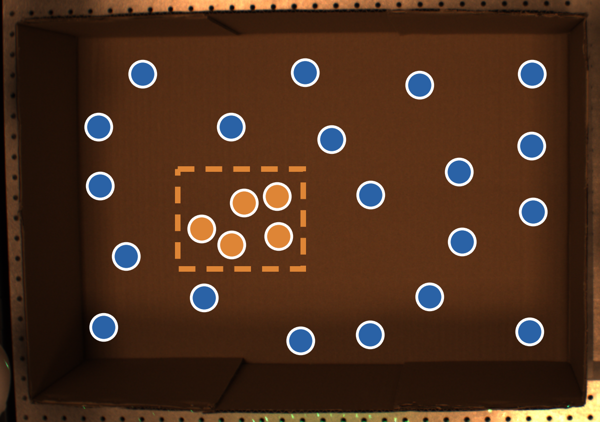

In [6]:
POSITION_BOX, POSITION_OBJ = "cardboard", "vase"   # box + object drawn above the position bar (REGION is held out for the vase only: candles train in it)
POSITION_N = {"train": 20, "unseen": 5}            # positions shown per group, spread out by farthest-point sampling
POS_STYLE = {"train": dict(c=BLUE, s=14, zorder=3), "unseen": dict(c=ORANGE, s=14, zorder=4)}

with contextlib.redirect_stdout(io.StringIO()): _samples, _ = load_splits()
METAS = list(_samples.values())
from score import sample_dir
from dataset import REGION   # (row0, row1, col0, col1) of the held-out floor region, as box fractions

def spread(pts, n):
    """n of the points, chosen by farthest-point sampling (deterministic: starts nearest the centroid), so the subset covers the same area"""
    if len(pts) <= n: return pts
    k = [int(np.argmin(((pts - pts.mean(0)) ** 2).sum(1)))]
    d = ((pts - pts[k[0]]) ** 2).sum(1)
    while len(k) < n:
        k.append(int(np.argmax(d))); d = np.minimum(d, ((pts - pts[k[-1]]) ** 2).sum(1))
    return pts[k]

def position_map(df, box=POSITION_BOX, obj=POSITION_OBJ, n=POSITION_N, width_in=1.2):
    """RGBA image: an empty-box overhead capture of `box` (same experiment and crop as the masks); the centre of mass of the ground-truth mask
    at n["train"] trained positions of `obj` (blue) and n["unseen"] unseen positions (orange), and the held-out REGION as a dashed orange box"""
    d = df[(df.model == "whisperbox") & (df.box == box)]
    sel = {"train": d[(d.group == "train") & (d.object == obj)], "unseen": d[(d.split == "unseen-position") & (d.object == obj)]}
    exp = {METAS[i]["experiment"] for g in sel.values() for i in g.i}; assert len(exp) == 1, exp; exp = exp.pop()
    crop = lambda m: (m["crop_left"], m["crop_right"], m["crop_top"], m["crop_bottom"])
    empty = next(m for m in METAS if m["experiment"] == exp and m["is_empty_box"])
    assert all(crop(METAS[i]) == crop(empty) for g in sel.values() for i in g.i), "masks and background must share the overhead crop"
    bg = Image.open(sample_dir(exp, int(empty["sample_id"]) if empty["sample_id"].isdigit() else -1, empty["position_id"], empty["speaker"]) / "image/02_cropped_overhead.png").convert("RGB")
    W, H = bg.size
    fig = plt.figure(figsize=(width_in, width_in * H / W)); ax = fig.add_axes([0, 0, 1, 1]); ax.imshow(bg); ax.axis("off")
    shown = {}
    for g, q in sel.items():
        com = []
        for i in q.drop_duplicates("position_id").i:   # one point per position (all speakers share it)
            m = METAS[i]; y = truth(m["experiment"], int(m["sample_id"]) if m["sample_id"].isdigit() else -1, m["position_id"], m["speaker"], 64, 64) > 0.5
            r, c = np.nonzero(y); com.append(((c.mean() + 0.5) / y.shape[1] * W, (r.mean() + 0.5) / y.shape[0] * H))   # mask pixel centres -> photo pixels
        com = spread(np.array(com), n[g])
        ax.scatter(com[:, 0], com[:, 1], edgecolors="white", linewidths=0.4, **POS_STYLE[g]); shown[g] = com
        print(f"{box} {obj} {g}: {len(com)} of {q.position_id.nunique()} positions")
    # held-out region, grown so it surrounds every shown unseen point (marker radius + HL_PAD) without touching it
    r0, r1, c0, c1 = REGION; px = W / (width_in * 72); m = (np.sqrt(POS_STYLE["unseen"]["s"]) / 2 + 0.4 + HL_PAD) * px
    u = shown["unseen"]; x0, x1 = min(c0 * W, u[:, 0].min() - m), max(c1 * W, u[:, 0].max() + m); y0, y1 = min(r0 * H, u[:, 1].min() - m), max(r1 * H, u[:, 1].max() + m)
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=ORANGE, lw=HL_LW * W / (width_in * 72) / px, ls=HL_DASH, zorder=5))
    buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=1000, transparent=True); plt.close(fig); buf.seek(0)
    return Image.open(buf).convert("RGBA")

FACTOR_IMAGES["position"] = position_map(df)
# dashed orange boxes around the unseen part of each factor image (fractions of the trimmed image, y from the top)
FACTOR_HIGHLIGHTS = {"object": px_box(FACTOR_IMAGES["object"], (690, 82, 1190, 728)),   # tomato sauce + coffee pot, in all_objects.png pixels
                     "speaker": rightmost_object(FACTOR_IMAGES["speaker"]),               # the unseen speaker
                     "rotation": stack(FACTOR_IMAGES["rotation"])[1][-1]}                  # the unseen angle
display(FACTOR_IMAGES["position"].resize((600, round(600 * FACTOR_IMAGES["position"].height / FACTOR_IMAGES["position"].width))))


## Panels
`draw_<panel>(ax, cfg)` plots one panel into a placed axes. `PANELS` holds each panel's size and position in the joint figure (a, b = row 1; c, d = row 2); `panel_fig(letter, cfg)` makes a standalone figure with an axes of exactly the same size, so the panel is identical in both.

step 26.3 pt, gap 0.36 in, figure 3.25 x 4.13 in


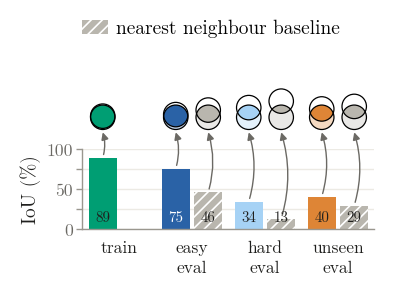

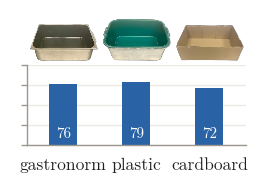

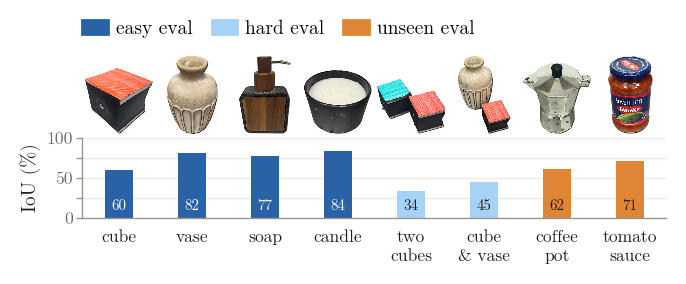

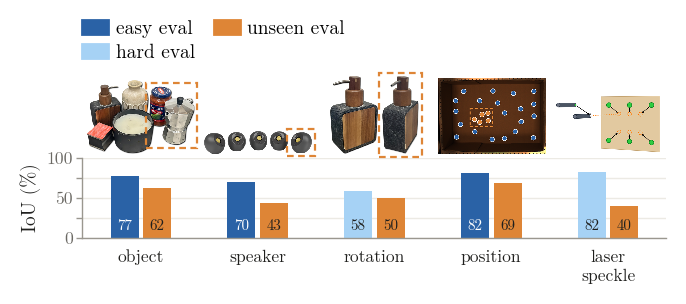

In [7]:
def draw_generalization(ax, cfg):
    gen = cfg["generalization"]
    style_ax(ax, (-0.5, len(gen) - 0.5), ylabel(cfg)); off = bar_w(ax) * PAIR_OFF
    for i, v in enumerate(gen.values()):
        draw_bar(ax, i - off, v["whisperbox"], GROUP_COLOR[v["group"]])
        venn_above(ax, i - off, mean_of(v["whisperbox"]), GROUP_COLOR[v["group"]])
        if v["nearest_neighbour"] is None: continue   # no baseline bar for train (its slot stays empty, so the spacing is unchanged)
        draw_bar(ax, i + off, v["nearest_neighbour"], NN_GRAY, hatch=HATCH)
        venn_above(ax, i + off, mean_of(v["nearest_neighbour"]), NN_GRAY)
    xlabels(ax, range(len(gen)), list(gen))

def draw_speakers(ax, cfg):   # kept, not part of the figure
    spk = cfg["speakers"]
    style_ax(ax, (-0.5, len(spk) - 0.5), None)
    for i, v in enumerate(spk.values()): draw_bar(ax, i, v, BLUE)
    xlabels(ax, range(len(spk)), list(spk))

def object_xs(objs):
    xs, x = [], 0.0
    for i, o in enumerate(objs):
        if i: x += 1.0 + float(o.get("gap_before", 0.0))
        xs.append(x)
    return xs

def draw_objects(ax, cfg):
    objs = cfg["objects"]; xs = object_xs(objs)
    style_ax(ax, (-0.5, xs[-1] + 0.5), ylabel(cfg))
    for x, o in zip(xs, objs): draw_bar(ax, x, o["iou"], GROUP_COLOR[o.get("group", "frequent")])
    thumbs_above(ax, xs, [o["image"] for o in objs])
    xlabels(ax, xs, [o["name"] for o in objs])

def draw_boxes(ax, cfg):
    boxes = cfg["boxes"]; xs = list(range(len(boxes)))
    style_ax(ax, (-0.5, len(boxes) - 0.5), None)
    for x, b in zip(xs, boxes): draw_bar(ax, x, b["iou"], GROUP_COLOR[b.get("group", "frequent")])
    thumbs_above(ax, xs, [b["image"] for b in boxes])
    xlabels(ax, xs, [b["name"] for b in boxes])

def draw_factors(ax, cfg):
    fac = cfg["factors"]
    style_ax(ax, (-0.5, len(fac) - 0.5), ylabel(cfg)); off = bar_w(ax) * PAIR_OFF
    for i, v in enumerate(fac.values()):
        draw_bar(ax, i - off, v["seen"], GROUP_COLOR[v.get("seen_group", "frequent")]); draw_bar(ax, i + off, v["unseen"], ORANGE)
    imgs = [FACTOR_IMAGES.get(k.replace("\n", " ")) for k in fac]
    hls = {(id(im) if isinstance(im, Image.Image) else im): FACTOR_HIGHLIGHTS[k.replace("\n", " ")] for k, im in zip(fac, imgs) if k.replace("\n", " ") in FACTOR_HIGHLIGHTS}
    thumbs_above(ax, range(len(fac)), imgs, highlights=hls)   # centred over the pair
    xlabels(ax, range(len(fac)), list(fac))

# three rows in one column, ONE step (width of one x unit) everywhere: the object row fills the width, row 1 takes the rest as the gap between its panels
DRAW = {"generalization": draw_generalization, "objects": draw_objects, "seen_unseen": draw_factors, "boxes": draw_boxes}
units = {"generalization": len(cfg["generalization"]), "objects": object_xs(cfg["objects"])[-1] + 1, "seen_unseen": len(cfg["factors"]), "boxes": len(cfg["boxes"])}
USABLE = W_IN - LEFT - RIGHT
STEP_PT = 72 * USABLE / units["objects"]
GAP = USABLE - (units["generalization"] + units["boxes"]) * STEP_PT / 72   # between generalization and boxes
IMG_IN = (THUMB_H + THUMB_GAP) / 72
VENN_IN = (VENN_LIFT + 4 * VENN_R + VENN_LW) / 72   # tallest Venn diagram (IoU 0) above the generalization bars
assert 2 * VENN_R + VENN_LW < 2 * PAIR_OFF * BAR_W_IN * 72, "Venn diagrams of the two bars of a pair must not touch"
width = {k: u * STEP_PT / 72 for k, u in units.items()}
width["seen_unseen"] = USABLE   # bottom row as wide as the object row (wider step, room for an image above each factor); bars and pair spacing unchanged
PANELS, top, letters = {}, LEGEND_H_IN, iter("abcd")   # letter -> (name, draw, x0 in, top in, width in)
for j, row in enumerate(ROWS):
    if j: top += ROW_GAP
    top += BAND_IN + max([IMG_IN if k in ("objects", "boxes") or (k == "seen_unseen" and FACTOR_IMAGES) else VENN_IN if k == "generalization" else 0 for k in row])   # room above the axes: images / Venn diagrams
    x0 = LEFT
    for k in row: PANELS[next(letters)] = (k, DRAW[k], x0, top, width[k]); x0 += width[k] + GAP
    top += PLOT_H + LABEL_BELOW_IN
H_IN = top + 0.02
print(f"step {STEP_PT:.1f} pt, gap {GAP:.2f} in, figure {W_IN} x {H_IN:.2f} in")

def panel_fig(letter, cfg):
    """one panel on its own; the axes has the same size in inches as in plot_all. Legend: only what the panel needs beyond its x labels"""
    name, draw, x0, _, w = PANELS[letter]
    left = LEFT if x0 == LEFT else 0.06
    top, bottom = {"seen_unseen": 0.30, "generalization": 0.32 + VENN_IN}.get(name, 0.20) + (IMG_IN if name in ("objects", "boxes") or (name == "seen_unseen" and FACTOR_IMAGES) else 0), LABEL_BELOW_IN + 0.02
    fig = plt.figure(figsize=(left + w + RIGHT + 0.02, top + PLOT_H + bottom))
    W, H = fig.get_size_inches()
    draw(fig.add_axes([left / W, bottom / H, w / W, PLOT_H / H]), cfg)
    kw = dict(bbox_to_anchor=(left / W, 1 - 0.02 / H), loc="upper left", **LEGEND_KW)
    if name == "generalization": fig.legend(handles=[nn_patch()], **kw)
    if name == "seen_unseen": fig.legend(handles=group_patches(list(dict.fromkeys([v.get("seen_group", "frequent") for v in cfg["factors"].values()] + ["unseen"]))), ncol=2, **kw)
    if name == "objects": fig.legend(handles=group_patches(list(dict.fromkeys(o.get("group", "frequent") for o in cfg["objects"]))), ncol=3, **kw)
    return fig

figs = {k: panel_fig(k, cfg) for k in PANELS}
plt.show()

## Joint figure

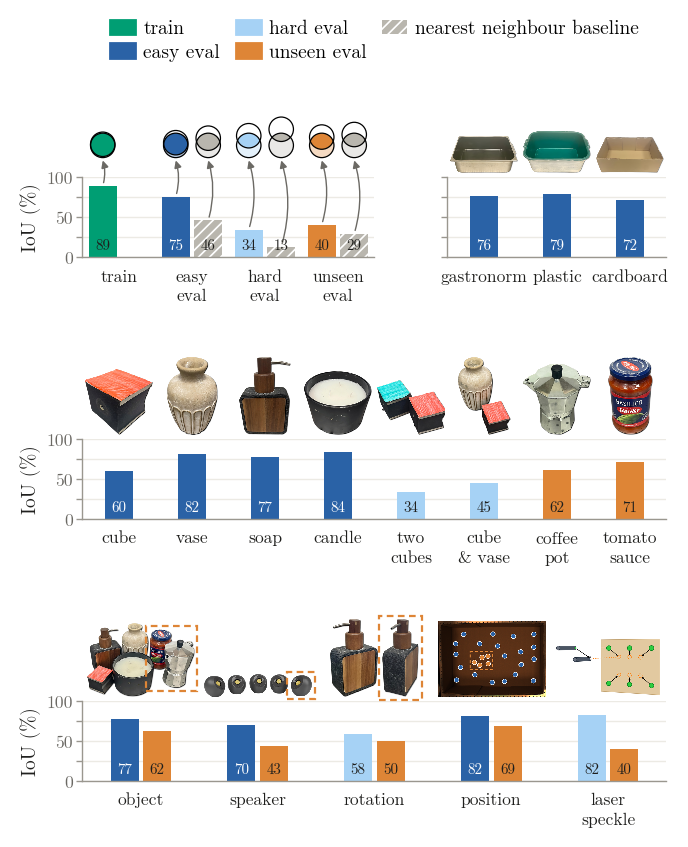

In [8]:
def plot_all(cfg):
    fig = plt.figure(figsize=(W_IN, H_IN))
    for _, draw, x0, top, w in PANELS.values():
        draw(fig.add_axes([x0 / W_IN, 1 - (top + PLOT_H) / H_IN, w / W_IN, PLOT_H / H_IN]), cfg)
    # legend: two rows across the very top, one-line labels
    handles = group_patches() + [nn_patch()]
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=((LEFT + (W_IN - LEFT - RIGHT) / 2) / W_IN, 1 - 0.02 / H_IN), ncol=3,
               **{**LEGEND_KW, "columnspacing": 0.8})
    return fig

joint = plot_all(cfg)
plt.show()


## Checks
Asserts for the checkable items of the style guides above, run on the joint figure and on every standalone panel.

In [9]:
def check_values(cfg):
    stats = [v for g in cfg["generalization"].values() for k, v in g.items() if k != "group" and v is not None] + list(cfg["speakers"].values()) \
            + [o["iou"] for o in cfg["objects"] + cfg["boxes"]] + [v for f in cfg["factors"].values() for k, v in f.items() if k in ("seen", "unseen")]
    for s in stats:
        assert 0 <= mean_of(s) <= 100, s
        if isinstance(s, dict): assert s["std"] >= 0 and s["n"] > 0, s
    assert all(o.get("group", "frequent") in GROUP_COLOR for o in cfg["objects"] + cfg["boxes"])
    for f in cfg["factors"].values():   # seen bar colour follows the training count of its condition
        if "seen_n_train" in f: assert f["seen_group"] == freq_group(f["seen_n_train"]), f

def ext(a, r): return a.get_window_extent(r)

def check_fig(fig):
    fig.canvas.draw(); r = fig.canvas.get_renderer(); px = fig.dpi / 72
    texts = [t for t in fig.findobj(mpl.text.Text) if t.get_visible() and t.get_text().strip() and t.figure is fig]
    # fonts: nothing below the in-bar numbers (5.4 pt; the 7 pt print guideline holds for legend / axis labels)
    assert min(t.get_fontsize() for t in texts) >= FS_VAL - 1e-6
    for t in texts:
        if t.get_fontsize() == FS_VAL: assert t.get_text().isdigit(), t.get_text()   # every value label: integer percent, no decimals
    assert not any(t.get_text().startswith("(") for t in texts)   # no panel titles / letters
    for ax in fig.axes:
        assert not ax.lines and not ax.collections, "no error bars"
        k = slot_pt(ax) / 72
        bars = [p for p in ax.patches if isinstance(p, Rectangle) and p.get_facecolor()[3] > 0]
        for p in bars:
            assert abs(p.get_width() * k - BAR_W_IN) < 1e-6, p.get_width() * k   # one physical bar width everywhere
            assert mpl.colors.to_hex(p.get_facecolor()).upper() in {c.upper() for c in PALETTE}, p.get_facecolor()   # only the five encoding colours
        imgs = [a for a in ax.artists if isinstance(a, AnnotationBbox) and isinstance(a.offsetbox, OffsetImage)]
        hs = [a.offsetbox.get_zoom() * a.offsetbox.get_data().shape[0] for a in imgs]
        assert all(h <= THUMB_H + 1e-6 for h in hs), hs   # thumbnails: all fitted into the same box
        for a in imgs:   # thumbnails sit above the axes, centred on their bar
            e, axb = ext(a, r), ax.get_window_extent(r)
            assert e.y0 >= axb.y1 + THUMB_GAP * px - 0.5, "thumbnail not above the axes"
            assert any(abs((e.x0 + e.x1) / 2 - ax.transData.transform((p.get_x() + p.get_width() / 2, 0))[0]) < 0.5 for p in bars) or \
                   any(abs((e.x0 + e.x1) / 2 - ax.transData.transform((x, 0))[0]) < 0.5 for x in range(len(cfg["factors"]))), "thumbnail not over a bar or a pair"
    # no two pieces of text / thumbnails / legends overlap (horizontal labels keep >= LABEL_PAD - 1 pt apart), everything inside the figure
    legends = fig.legends + [ax.get_legend() for ax in fig.axes if ax.get_legend()]
    leg_txt = {id(t) for l in legends for t in l.get_texts()}
    pad = (LABEL_PAD - 1) / 2 * px
    hpad = lambda b: mpl.transforms.Bbox.from_extents(b.x0 - pad, b.y0, b.x1 + pad, b.y1)   # horizontal only: lines of one label may touch
    boxes = [(t.get_text(), hpad(ext(t, r)), False) for t in texts if id(t) not in leg_txt and t.get_gid() != "venn_label"]   # Venn numbers sit inside their picture   # legend entries are checked as one legend box
    boxes += [("<img>", ext(a, r), False) for ax in fig.axes for a in ax.artists if isinstance(a, AnnotationBbox) and a.get_gid() != "highlight"]   # highlight boxes sit on their image
    boxes += [("<legend>", ext(l, r), False) for l in legends]
    fb = fig.bbox
    for n, p, _ in boxes: assert p.x0 >= fb.x0 - 1 and p.x1 <= fb.x1 + 1 and p.y0 >= fb.y0 - 1 and p.y1 <= fb.y1 + 1, f"outside the figure: {n!r}"
    bad = [(a, b) for i, (a, p, _) in enumerate(boxes) for b, q, _ in boxes[i + 1:] if p.overlaps(q)]
    assert not bad, f"overlaps: {bad}"
    return r

check_values(cfg)
rng = np.random.default_rng(0)
for iou in (0.0, 0.05, 0.13, 0.34, 0.5, 0.75, 0.89, 1.0):   # Venn geometry: Monte-Carlo IoU of the drawn circles = the requested IoU
    d = venn_distance(iou); pts = rng.uniform([-1, -1], [1 + d, 1], (400_000, 2))
    a, b = np.hypot(*pts.T) <= 1, np.hypot(pts[:, 0] - d, pts[:, 1]) <= 1
    assert abs((a & b).sum() / (a | b).sum() - iou) < 0.005, (iou, (a & b).sum() / (a | b).sum())
assert abs(joint.get_figwidth() - W_IN) < 1e-9   # CVPR column width, include at native size
r = check_fig(joint)
step_in, pair_in = STEP_PT / 72, 2 * PAIR_OFF * BAR_W_IN
for (name, _, x0, top, w), ax in zip(PANELS.values(), joint.axes):
    p = ax.get_position()
    step = 72 * USABLE / units[name] if name == "seen_unseen" else STEP_PT   # bottom row: its own (wider) step, filling the width
    assert abs(slot_pt(ax) - step) < 1e-9, name                       # one step (x-label spacing) in rows 1-2
    step_in = step / 72
    cx = sorted(ax.transData.transform((b.get_x() + b.get_width() / 2, 0))[0] / joint.dpi for b in ax.patches
                if isinstance(b, Rectangle) and b.get_facecolor()[3] > 0)
    d = np.round(np.diff(cx), 6)
    ok = {round(pair_in, 6), round(step_in - pair_in, 6), round(step_in, 6)} if name in ("generalization", "seen_unseen") else {round(step_in, 6), round(step_in * (1 + GROUP_GAP), 6)}
    assert set(d) <= ok, (name, set(d), ok)                             # same bar spacing within a pair, between labels, between object groups
rows = [[joint.axes[list(PANELS).index(k)].get_position() for k, v in PANELS.items() if v[0] in row] for row in ROWS]
assert all(abs(row[0].x0 * W_IN - LEFT) < 1e-9 for row in rows)                           # every row starts at the same left edge
assert all(abs(row[-1].x1 * W_IN - (W_IN - RIGHT)) < 1e-9 for row in rows)               # every row ends at the same right edge
assert GAP >= STEP_PT / 72 - 1e-9, "gap between panels at least one step"
assert all(abs(q.y0 - row[0].y0) < 1e-9 for row in rows for q in row)                    # panels of a row share top and bottom
for f in figs.values(): check_fig(f)
for k, f in figs.items():   # standalone panel axes = joint panel axes, in inches
    p, q = f.axes[0].get_position(), joint.axes[list(PANELS).index(k)].get_position()
    assert abs(p.width * f.get_figwidth() - q.width * W_IN) < 1e-9 and abs(p.height * f.get_figheight() - q.height * H_IN) < 1e-9
print(f"all checks passed; figure {W_IN} x {H_IN:.2f} in, step {STEP_PT:.1f} pt")


all checks passed; figure 3.25 x 4.13 in, step 26.3 pt


## Save
Every panel and the joint figure as SVG (text as paths) and PDF (fonts embedded); the joint figure also as PNG (600 dpi) in `OUT_DIR`: `fig_quant_{generalization,objects,seen_unseen,boxes,all}`.

In [10]:
out = ROOT / OUT_DIR; out.mkdir(parents=True, exist_ok=True)
for name, f in [*((PANELS[k][0], f) for k, f in figs.items()), ("all", joint)]:
    stem = out / f"fig_quant_{name}"
    f.savefig(f"{stem}.svg"); f.savefig(f"{stem}.pdf")   # vector: SVG (text as paths) + PDF (fonts embedded)
    if f is joint: f.savefig(f"{stem}.png", dpi=600)    # PNG preview of the joint figure only
    print(stem.relative_to(ROOT), f"{f.get_figwidth():.2f} x {f.get_figheight():.2f} in")

figures/quantitative_results/fig_quant_generalization 1.81 x 1.37 in
figures/quantitative_results/fig_quant_boxes 1.20 x 1.31 in


figures/quantitative_results/fig_quant_objects 3.27 x 1.31 in


figures/quantitative_results/fig_quant_seen_unseen 3.27 x 1.41 in


figures/quantitative_results/fig_quant_all 3.25 x 4.13 in
